<a href="https://colab.research.google.com/github/ethereal-arko/Medical_Insurance_Cost_Prediction/blob/main/Medical_Insurance_Cost_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Medical Insurance Cost Prediction using Linear Regression

## Objective
The objective of this project is to predict individual medical insurance charges using demographic and lifestyle-related features.

## Machine Learning Approach
- **Learning Type:** Supervised Learning
- **Problem Type:** Regression
- **Algorithm:** Linear Regression
- **Target Variable:** `charges`

## Dataset Features
- Age
- Sex
- BMI
- Number of Children
- Smoking Status
- Residential Region

## Project Workflow
1. Load and inspect the dataset.
2. Perform exploratory data analysis (EDA).
3. Check data quality and preprocess features.
4. Split the data into training and testing sets.
5. Train a Linear Regression model.
6. Evaluate the model using appropriate regression metrics.
7. Build a prediction system.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Load the dataset
insurance_data = pd.read_csv('/content/insurance.csv')

# Display the first five rows
display(insurance_data.head())


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



## Dataset Inspection and Data Quality

In this section, we will:
- Check the number of rows and columns.
- Inspect column names and data types.
- Identify missing values.
- Examine statistical summaries.
- Check for duplicate records.


In [3]:

# Check the number of rows and columns
print("Dataset shape:", insurance_data.shape)

# Inspect column names, data types, and non-null counts
print("\nDataset information:")
insurance_data.info()

# Check missing values
print("\nMissing values in each column:")
print(insurance_data.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", insurance_data.duplicated().sum())

# View statistical summaries of numerical columns
print("\nStatistical summary:")
display(insurance_data.describe())


Dataset shape: (1338, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of duplicate rows: 1

Statistical summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



## Data Cleaning and Categorical Feature Inspection

The dataset contains one exact duplicate row and no missing values.

In this section, we will:
1. Inspect the duplicated record.
2. Remove the exact duplicate.
3. Check the unique categories and their frequencies.
4. Confirm the cleaned dataset dimensions.


In [4]:

# Display the duplicated record(s)
print("Duplicated records:")
display(insurance_data[insurance_data.duplicated(keep=False)])

# Remove exact duplicate rows
insurance_data = insurance_data.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", insurance_data.shape)
print("Remaining duplicate rows:", insurance_data.duplicated().sum())

# Inspect categorical columns
categorical_columns = ['sex', 'smoker', 'region']

for column in categorical_columns:
    print(f"\nValue counts for {column}:")
    print(insurance_data[column].value_counts())


Duplicated records:


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Shape after removing duplicates: (1337, 7)
Remaining duplicate rows: 0

Value counts for sex:
sex
male      675
female    662
Name: count, dtype: int64

Value counts for smoker:
smoker
no     1063
yes     274
Name: count, dtype: int64

Value counts for region:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64



## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution of individual features and identify relationships between the input variables and insurance charges.

We will visualize:
- Age distribution
- BMI distribution
- Insurance charge distribution
- Categorical feature frequencies
- Insurance charges by smoking status


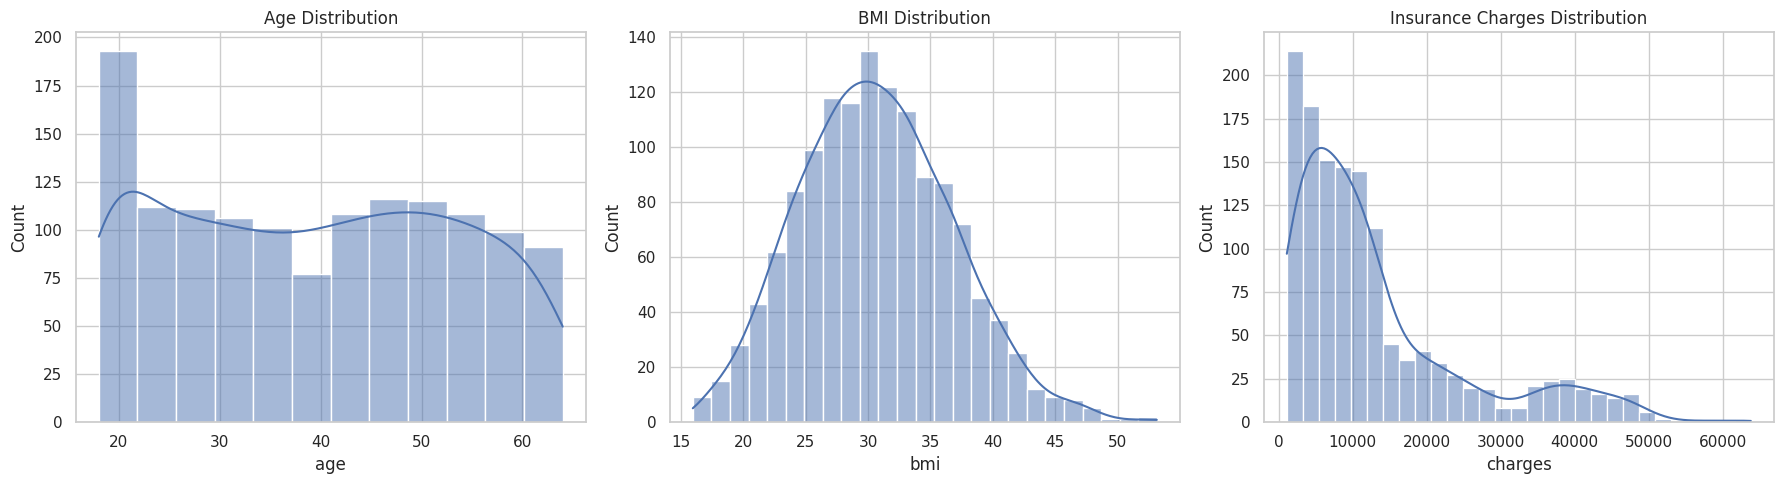

In [5]:

# Set a consistent plotting style
sns.set_theme(style="whitegrid")

# Create histograms for numerical features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=insurance_data, x='age', kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(data=insurance_data, x='bmi', kde=True, ax=axes[1])
axes[1].set_title('BMI Distribution')

sns.histplot(data=insurance_data, x='charges', kde=True, ax=axes[2])
axes[2].set_title('Insurance Charges Distribution')

plt.tight_layout()
plt.show()


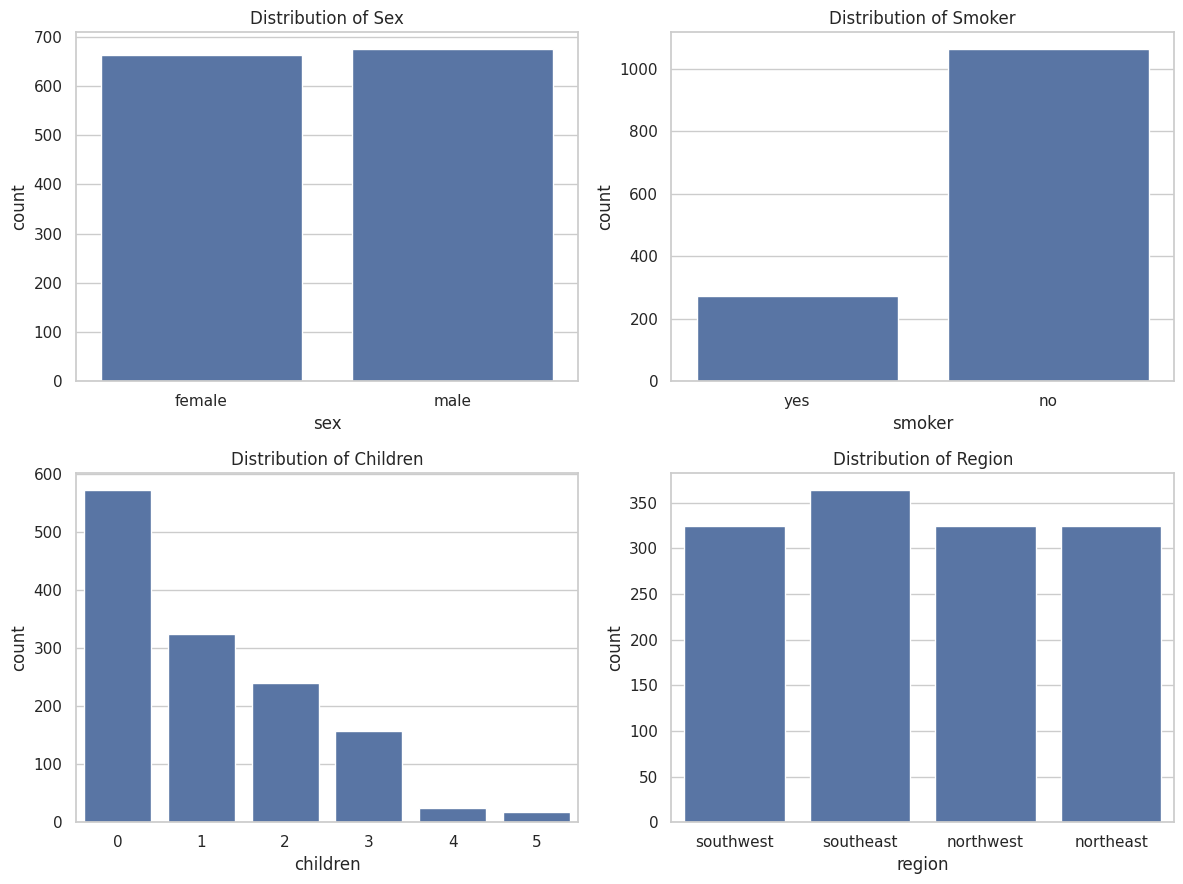

In [6]:

categorical_columns = ['sex', 'smoker', 'children', 'region']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    sns.countplot(data=insurance_data, x=column, ax=ax)
    ax.set_title(f'Distribution of {column.capitalize()}')

plt.tight_layout()
plt.show()


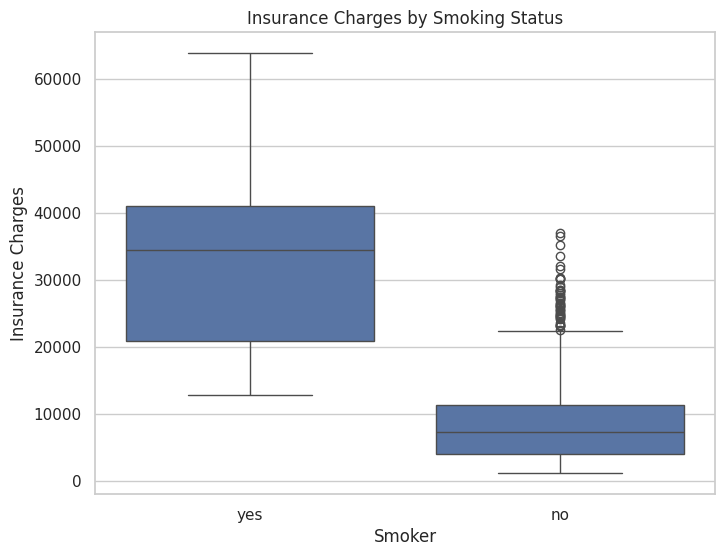

In [7]:

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=insurance_data,
    x='smoker',
    y='charges'
)

plt.title('Insurance Charges by Smoking Status')
plt.xlabel('Smoker')
plt.ylabel('Insurance Charges')
plt.show()



## Feature Encoding and Data Preparation

Machine learning models generally require numerical input features. Therefore, categorical variables must be converted into a suitable numerical representation.

We will:
1. Separate the input features (X) and target variable (y).
2. Apply one-hot encoding to categorical features.
3. Inspect the transformed dataset.


In [8]:

# Separate input features and target variable
X = insurance_data.drop(columns=['charges'])
y = insurance_data['charges']

# Identify categorical columns
categorical_columns = ['sex', 'smoker', 'region']

# Apply one-hot encoding
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Inspect the encoded features
print("Encoded feature columns:")
print(X_encoded.columns.tolist())

print("\nEncoded dataset shape:", X_encoded.shape)

display(X_encoded.head())


Encoded feature columns:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Encoded dataset shape: (1337, 8)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0



## Splitting the Dataset

We will split the cleaned dataset into:
- **Training set (80%):** Used to train the model.
- **Testing set (20%):** Used to evaluate performance on unseen records.

A fixed random state makes the split reproducible.


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Full dataset:", X_encoded.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Full dataset: (1337, 8)
Training features: (1069, 8)
Testing features: (268, 8)
Training targets: (1069,)
Testing targets: (268,)



## Model Training: Linear Regression

Linear Regression learns the relationship between the input features and the target variable, insurance charges.

The model estimates coefficients for the input features and an intercept to minimize the sum of squared prediction errors on the training data.


In [10]:

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

# Display the intercept
print("\nModel intercept:", model.intercept_)

# Display feature coefficients
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficients['Coefficient'] = coefficients['Coefficient'].round(2)

display(coefficients.sort_values(
    by='Coefficient',
    ascending=False
).reset_index(drop=True))


Linear Regression model trained successfully.

Model intercept: -11092.65229594595


,Feature,Coefficient
0,smoker_yes,23077.76
1,children,533.01
2,bmi,318.70
3,age,248.21
4,sex_male,-101.54
5,region_northwest,-391.76
6,region_southwest,-659.14
7,region_southeast,-838.92



## Model Evaluation

We will evaluate the model on both training and testing data using:

- **R² Score:** Measures how much variation in the target is explained by the model.
- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted charges.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more strongly.

The testing metrics provide the main estimate of performance on unseen data.


In [11]:

# Generate predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate evaluation metrics
train_r2 = metrics.r2_score(y_train, y_train_pred)
test_r2 = metrics.r2_score(y_test, y_test_pred)

test_mae = metrics.mean_absolute_error(y_test, y_test_pred)
test_mse = metrics.mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)

print("Training R² Score:", round(train_r2, 4))
print("Testing R² Score:", round(test_r2, 4))
print("Testing MAE:", round(test_mae, 2))
print("Testing RMSE:", round(test_rmse, 2))


Training R² Score: 0.7299
Testing R² Score: 0.8069
Testing MAE: 4177.05
Testing RMSE: 5956.34



## Actual vs Predicted Values and Residual Analysis

We will compare actual insurance charges with the model's predictions and examine residuals.

A good prediction model should generally produce points close to the diagonal in the actual-versus-predicted plot. Residual analysis helps identify systematic prediction errors and changing error variance.


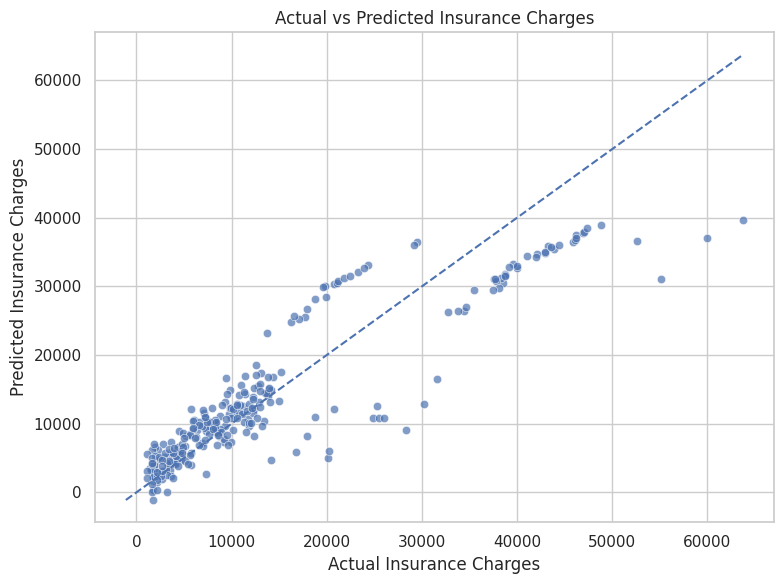

In [12]:

# Plot actual versus predicted charges
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.7)

# Reference line: perfect predictions
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Insurance Charges')
plt.ylabel('Predicted Insurance Charges')
plt.title('Actual vs Predicted Insurance Charges')
plt.tight_layout()
plt.show()


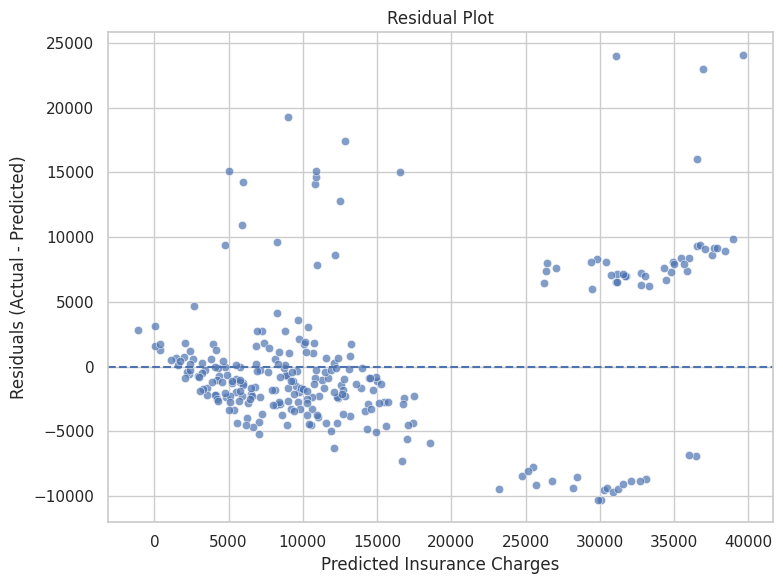

Mean residual: 425.26


In [13]:

# Calculate residuals
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.7)
plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Insurance Charges')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot')
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))



## Insurance Cost Prediction System

This system accepts an individual's demographic and lifestyle-related information and predicts estimated medical insurance charges using the trained Linear Regression model.

The input features must use the same names, order, and encoding as the training data.


In [14]:

def predict_insurance_charges(age, sex, bmi, children, smoker, region):
    # Create a DataFrame with the original input features
    input_data = pd.DataFrame([{
        'age': age,
        'sex': sex,
        'bmi': bmi,
        'children': children,
        'smoker': smoker,
        'region': region
    }])

    # Apply the same one-hot encoding as the training data
    input_encoded = pd.get_dummies(
        input_data,
        columns=['sex', 'smoker', 'region'],
        drop_first=True,
        dtype=int
    )

    # Ensure the input has exactly the training feature columns
    input_encoded = input_encoded.reindex(
        columns=X_encoded.columns,
        fill_value=0
    )

    # Predict insurance charges
    prediction = model.predict(input_encoded)[0]

    return prediction


# Example prediction
estimated_charges = predict_insurance_charges(
    age=31,
    sex='female',
    bmi=25.74,
    children=0,
    smoker='no',
    region='southwest'
)

print(f"Estimated Insurance Charges: {estimated_charges:.2f}")


Estimated Insurance Charges: 4805.26



## Conclusion

In this project, a Linear Regression model was developed to predict medical insurance charges using demographic and lifestyle-related features.

The dataset was inspected and cleaned by removing one exact duplicate record. Categorical variables were transformed using one-hot encoding, and the dataset was divided into training and testing sets.

The model achieved a test R² score of 0.8069, with a Mean Absolute Error (MAE) of 4177.05 and a Root Mean Squared Error (RMSE) of 5956.34.

Smoking status had a large positive coefficient in the fitted model, indicating a strong association with higher predicted insurance charges, holding the other encoded features constant.

Although the model provides a useful baseline, its predictions contain errors. Further improvements could include cross-validation, residual diagnostics, comparison with regularized linear models, and tree-based regression algorithms.

The model's predictions should be interpreted as estimates rather than guaranteed insurance costs.
